# LAB 5 — Neural Networks: from linear to nonlinear models

**This sheet is for you. Preparing for the exam starts here.** Work in pairs: explain your predictions to one another before running the next cell.

**PREDICT → RUN & OBSERVE → EXPLAIN → EXPERIMENT**. Running the code is useful, but the goal is to understand what the experiment shows. Write short answers in your Thinking Sheet.

# First part: Comparison of classifiers on simulated data

In [1]:
from sklearn.datasets import make_moons, make_circles, make_classification, make_blobs
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier # MultiLayer Perceptron Classifier
from matplotlib.colors import ListedColormap

The following are two useful functions for plotting a dataset (only training, or all data split into training and test) and the decision boundary of a model and the data

In [2]:
def plot_dataset(X_train, y_train, X_test=None, y_test=None):
    # -- function that plots the datapoints
    h = 0.02 # -- h is the step length
    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # -- just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(1,1,1)
    ax.set_title("Input data")
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k")
    
    if X_test is not None and y_test is not None:
        # -- Plot the testing points
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.2, edgecolors="k")
    
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())

In [3]:
def plot_model(input_model, X_train, y_train, X_test, y_test):
    # -- function that plots the datapoints and decision boundaries of input_model
    h = 0.02
    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # -- just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(1, 1, 1)
    
    ax.set_title("Model decision boundary")
    # -- Plot the decision boundary. For that, we will assign a color to each
    # -- point in the mesh [x_min, x_max] x [y_min, y_max].
    if hasattr(input_model, "decision_function"):
        Z = input_model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    else:
        Z = input_model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]

    # -- Put the result into a color plot
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cm, alpha = 0.8)

    # -- Plot the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c = y_train, cmap = cm_bright, edgecolors = "k")
    # -- Plot the testing points
    ax.scatter(X_test[:, 0], X_test[:, 1], c = y_test, cmap = cm_bright, edgecolors = "k", alpha = 0.2)

    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())

### Investigation 1 — Almost linearly separable data

We generate two-dimensional observations, split them into training and test sets, and standardize using **training statistics only**. We will compare the Perceptron with a fully connected feedforward neural network, which is a multilayer perceptron (MLP). A two-dimensional plot makes the learned decision regions visible.

**PREDICT (write first):** Will a linear classifier and an MLP necessarily produce different decision boundaries on nearly linearly separable data? Which model do you expect to have lower test error?

**RUN & OBSERVE:** Run the dataset and plotting cells, then train the Perceptron and the MLP. Compare both the plots and the reported errors. The background represents a model score or class probability (depending on the model); it is **not always a probability**.

**EXPLAIN:** What does the decision boundary tell you that the training error alone does not?


We start with an almost linearly separable dataset and compare the Perceptron with a neural network.

In [4]:
# -- generate a random n-classification dataset
X, y = make_classification(
    n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1
)

# -- add noise to points exploiting a uniform distribution
# -- the aim is to get closer to a non-linearly separable dataset 
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size = X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state = 42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Let's plot the training dataset.

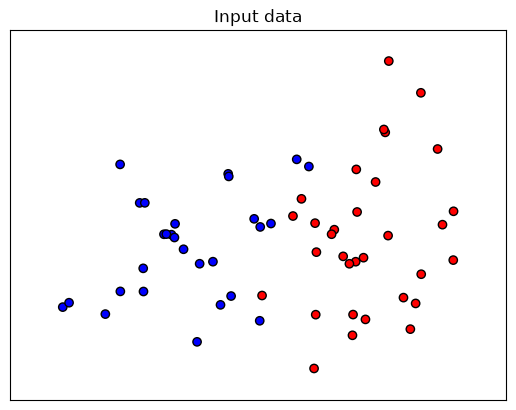

In [5]:
plot_dataset(X_train_scaled, y_train)

Let's now print all data (i.e., train and and test). The points in the test set are the most transparent that will be displayed.

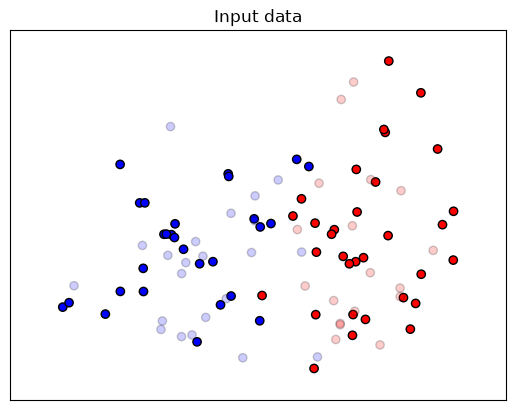

In [6]:
plot_dataset(X_train_scaled, y_train, X_test_scaled, y_test)

Train a Perceptron, inspect its linear decision boundary, and compare training and test errors. The plot background is the decision score representation, not a calibrated probability.

Training error:, 0.03333
Test error:, 0.05000


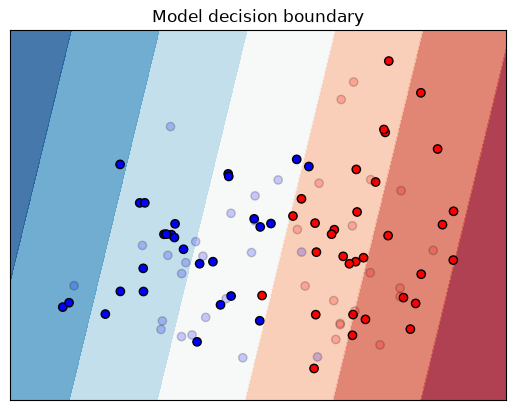

In [7]:
perceptron = Perceptron(random_state = 11)
perceptron.fit(X_train_scaled, y_train)

plot_model(perceptron, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error:, {(1.0 - perceptron.score(X_train_scaled, y_train)):.5f}')

print(f'Test error:, {(1.0 - perceptron.score(X_test_scaled, y_test)):.5f}')

Let's try with a NN.

Training error: 0.01667
Test error: 0.05000


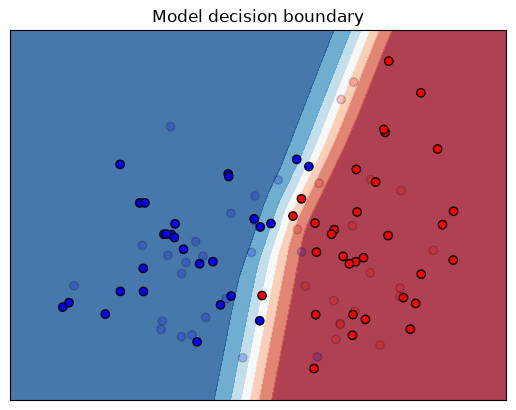

In [12]:
# -- one hidden layer with size= 100, activation function = ReLU (see documentation)
mlp = MLPClassifier(max_iter = 1000, activation='relu')
mlp.fit(X_train_scaled, y_train)

plot_model(mlp, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - mlp.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - mlp.score(X_test_scaled, y_test)):.5f}')

### Investigation 2 — When a straight line is not enough

`make_moons` produces curved class regions. We repeat the same preprocessing and comparison so that the main difference is the **geometry of the data**, not a new evaluation procedure.

**PREDICT:** Can a single linear decision boundary separate the two moons well? What extra flexibility might an MLP provide?

**RUN & OBSERVE:** Compare Perceptron and MLP training/test errors and the shape of their decision boundaries.

**EXPLAIN:** Does a lower training error necessarily imply a lower test error?

**EXPERIMENT:** Change the noise level in `make_moons`, keeping the split seed fixed. Predict first, then check how both models respond.


---

Let's try now with some more complex dataset.

In [13]:
X, y = make_moons(noise = 0.3, random_state = 0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state = 42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Let's plot the training data.

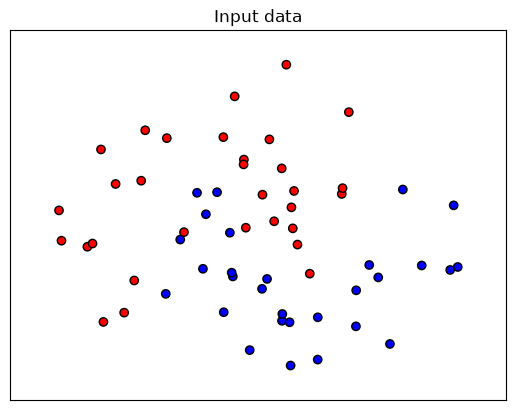

In [14]:
plot_dataset(X_train_scaled, y_train)

Let's plot all the data.

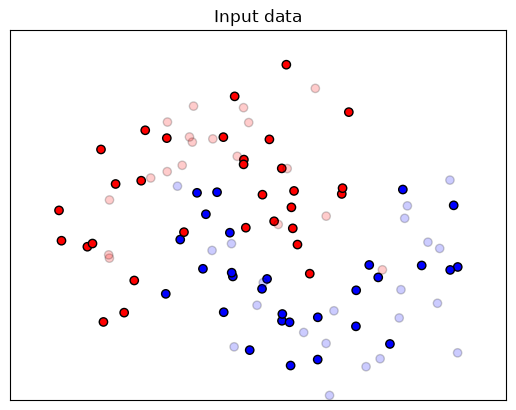

In [15]:
plot_dataset(X_train_scaled, y_train, X_test_scaled, y_test)

Let's run the perceptron.

Training error: 0.21667
Test error: 0.22500


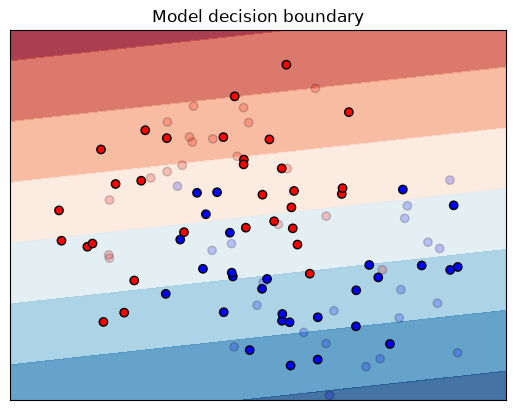

In [16]:
perceptron = Perceptron(random_state = 11)
perceptron.fit(X_train_scaled, y_train)

plot_model(perceptron, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - perceptron.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - perceptron.score(X_test_scaled, y_test)):.5f}')

Let's try the NN

Training error: 0.01667
Test error: 0.05000


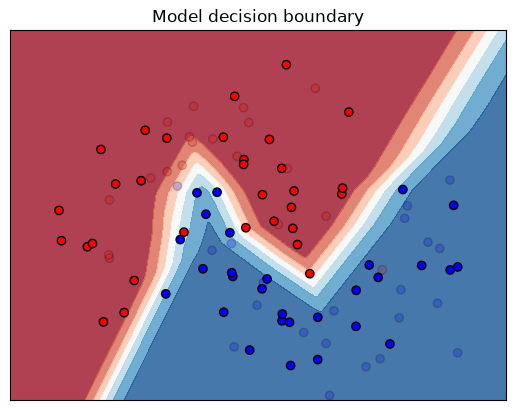

In [17]:
mlp = MLPClassifier(max_iter = 1500)
# -- Note that with max_iter = 1000 the model is not converging. (see 'tol' parameter). Try to re-train with max_iter = 1500
mlp.fit(X_train_scaled, y_train)

plot_model(mlp, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - mlp.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - mlp.score(X_test_scaled, y_test)):.5f}')

### Going further — Concentric circles

The circles dataset provides another example of a nonlinear classification pattern. Compare the Perceptron and MLP. What does the MLP learn that the Perceptron cannot represent? 


In [23]:
X, y = make_circles(noise = 0.2, factor = 0.5, random_state = 1)

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.4, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Let's plot the training data.

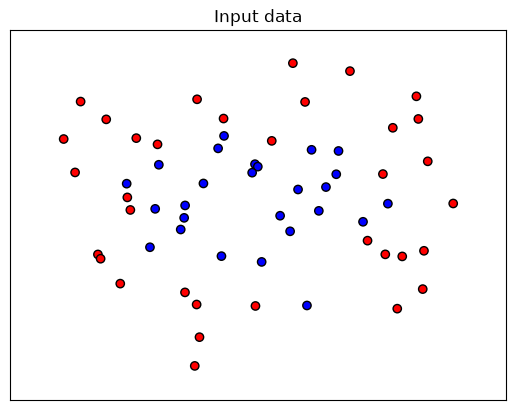

In [24]:
plot_dataset(X_train_scaled, y_train)

Let's plot all the data.

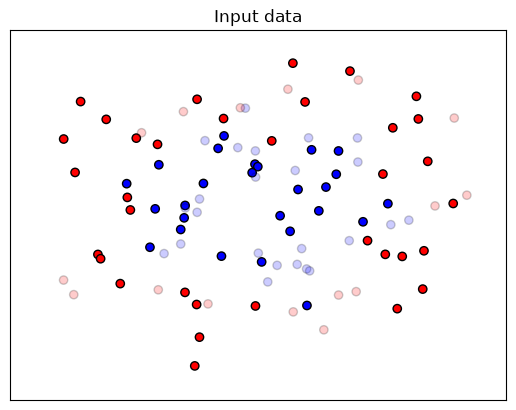

In [25]:
plot_dataset(X_train_scaled, y_train, X_test_scaled, y_test)

Let's run the perceptron

Training error: 0.50000
Test error: 0.47500


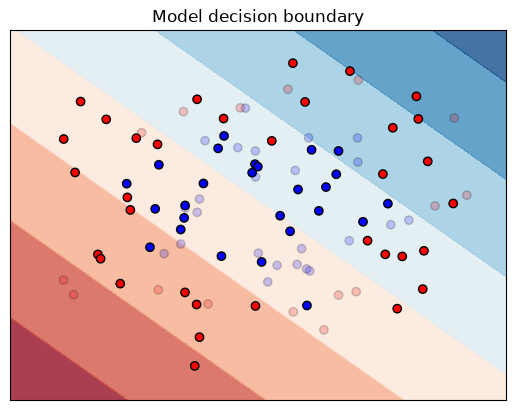

In [26]:
perceptron = Perceptron(random_state = 11)
perceptron.fit(X_train_scaled, y_train)

plot_model(perceptron, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - perceptron.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - perceptron.score(X_test_scaled, y_test)):.5f}')

Let's run the NN

Training error: 0.03333
Test error: 0.12500


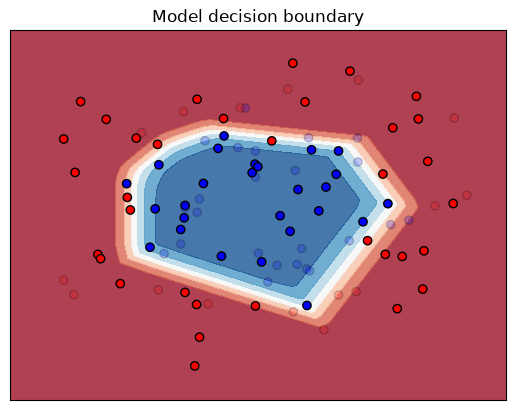

In [27]:
mlp = MLPClassifier(max_iter = 1000)
mlp.fit(X_train_scaled, y_train)

plot_model(mlp, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - mlp.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - mlp.score(X_test_scaled, y_test)):.5f}')

### Going further — Gaussian blobs

Here the data have a different geometry again. Use the same train/test evaluation to investigate whether a more flexible classifier is always necessary. **Predict** which model will be sufficient before running the cells. This section is optional.


---

Let's now consider the blobs datasets

In [28]:
# -- make_blobs dataset

# -- generate the dataset
X, y = make_blobs(n_samples = 1000, centers = 2, n_features = 2, center_box=(-7.5, 7.5), random_state = 37, cluster_std = 2.8)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# -- scale data
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

Let's plot all the data.

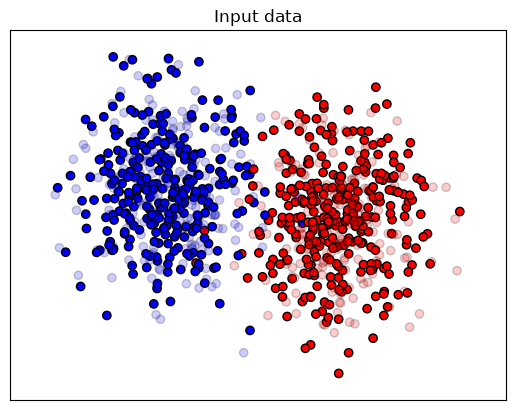

In [29]:
plot_dataset(X_train_scaled, y_train, X_test_scaled, y_test)

Training error: 0.02833
Test error: 0.03750


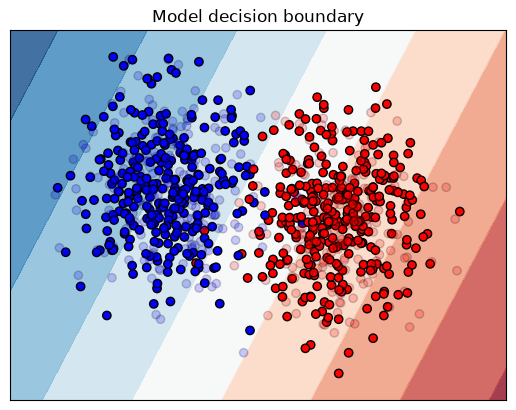

In [30]:
# -- perceptron
perceptron = Perceptron(random_state = 11)
perceptron.fit(X_train_scaled, y_train)

plot_model(perceptron, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - perceptron.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - perceptron.score(X_test_scaled, y_test)):.5f}')

Training error: 0.02167
Test error: 0.01750


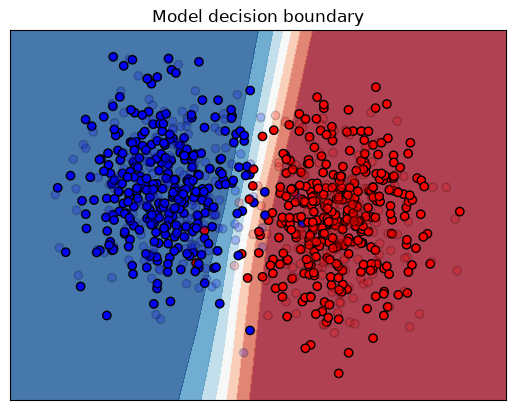

In [31]:
# -- NN (mlp)
mlp = MLPClassifier(max_iter = 1000)
mlp.fit(X_train_scaled, y_train)

plot_model(mlp, X_train_scaled, y_train, X_test_scaled, y_test)

print(f'Training error: {(1.0 - mlp.score(X_train_scaled, y_train)):.5f}')
print(f'Test error: {(1.0 - mlp.score(X_test_scaled, y_test)):.5f}')

# Part 2 — Neural networks for regression: house prices

We now move from **classification** to **regression**, using the original King County house-pricing example of the last lab. The model output is a continuous price, not a class label.

**What changes?** We compare regression models using their predictive performance on held-out data. The code reports `R²`

**Core questions:** Can a neural network represent a linear model? What changes as we increase hidden-layer width and depth? How can we select an architecture without looking at the test set?


# Second part: Regression on House Pricing Dataset
We consider a reduced version of a dataset containing house sale prices for King County, which includes Seattle. It includes homes sold between May 2014 and May 2015.

https://www.kaggle.com/harlfoxem/housesalesprediction

For each house we know 18 house features (e.g., number of bedrooms, number of bathrooms, etc.) plus its price, that is what we would like to predict.

In [32]:
# -- put here your ID_Number  (numero di matricola)
numero_di_matricola = 2223755

In [33]:
#import all packages needed
# %matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -- avoid convergence warnings from sklearn library
import warnings
warnings.filterwarnings("ignore")

### Load and inspect the data

We load `kc_house_data.csv`, drop rows containing missing values, and inspect the column names and first records. **Before running:** which column is the target, and which columns should be excluded from the inputs? Check that the column positions used below still match the supplied CSV.


Load the data, remove data samples/points with missing values (NaN) and take a look at them.

In [38]:
# -- load the dataset
df = pd.read_csv('kc_house_data/kc_house_data_future.csv', sep = ',')
# -- remove the data samples with missing values (NaN)
df = df.dropna() 

In [39]:
# -- print the column names and the first 5 rows of the dataframe
print(df.columns)
print('\n')
print(df.head())

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')


           id             date      price  bedrooms  bathrooms  sqft_living  \
0  3225069065  20140624T000000  3075000.0         4       5.00         4550   
1  3260800030  20140811T000000   335000.0         3       2.50         2440   
2  2747100024  20140619T000000   576000.0         3       2.50         1940   
3  5104530560  20150401T000000   208633.0         3       2.50         2040   
4  4330600350  20150115T000000   315000.0         3       2.25         2200   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0     18641     1.0           1     4  ...     10        2600           1950   
1      7632     2.0           0     0  ...      8        2440         

Extract input and output data. We want to predict the price by using features other than id as input.

In [41]:
Data = df.values
# -- m = number of input samples
m = Data.shape[0]
print("Amount of data:",m)
Y = Data[:m, 2]
X = Data[:m, 3:]

# -- print shapes
print("X shape: ", X.shape)
print("Y shape: ", Y.shape)

Amount of data: 2863
X shape:  (2863, 18)
Y shape:  (2863,)


## Data Pre-Processing

We split the data into 3 parts: one will be used for training and choosing the parameters, one for choosing among different models, and one for testing. The part for training and choosing the parameters will consist of $2/3$ of all samples, the one for choosing among different models will consist of $1/6$ of all samples, while the other part consists of the remaining $1/6$-th of all samples.

In [42]:
# -- Split data into train (2/3 of samples), validation (1/6 of samples), and test data (the rest)
m_train = int(2/3*m)
m_val = int((m-m_train)/2)
m_test = m - m_train - m_val
print("Amount of data for training and deciding parameters:", m_train)
print("Amount of data for validation (choosing among different models):", m_val)
print("Amount of data for test:", m_test)

from sklearn.model_selection import train_test_split

X_train_and_val, X_test, Y_train_and_val, Y_test = train_test_split(X, Y, test_size = m_test/m, random_state = numero_di_matricola)
X_train, X_val, Y_train, Y_val = train_test_split(X_train_and_val, Y_train_and_val, 
                                                  test_size = m_val/(m_train + m_val), random_state = numero_di_matricola)

Amount of data for training and deciding parameters: 1908
Amount of data for validation (choosing among different models): 477
Amount of data for test: 478


Let's standardize the data.

In [43]:
# -- Data pre-processing
from sklearn import preprocessing
scaler = preprocessing.StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
X_train_and_val_scaled = scaler.transform(X_train_and_val)

### Investigation 3 — A very small neural network

We first fit an `MLPRegressor` with **one hidden unit**. `hidden_layer_sizes=(1,)` means one hidden layer containing one unit; it does not mean one input feature. We use the `lbfgs` solver to optimize its parameters.

**PREDICT:** Will this network necessarily behave like linear regression? Which activation function is used by default?

**RUN & OBSERVE:** Look at training and validation scores. The helper below prints the weights and biases so you can connect the numerical output to the architecture.

**EXPLAIN:** What does a weight matrix shape tell you about the number of units in consecutive layers?


## What is LBFGS?
LBFGS (Limited-memory Broyden–Fletcher–Goldfarb–Shanno) is an optimization algorithm used to train neural networks 
by minimizing the loss function. Unlike Gradient Descent, it uses information from previous gradients to approximate second-order information (the curvature of the loss function), often achieving faster convergence on small datasets.

For this lab, you do not need to understand the details of LBFGS. Just remember that it is an alternative optimization method to GD and SGD, which we studied in class.

## Neural Networks
Let's start by learning a simple neural network with 1 hidden node.
Note: we are going to use the input parameter solver='lbfgs' and random_state=numero_di_matricola to fix the random seed (so results are reproducible).

We hereby define a function to train an MLPRegressor on the (already scaled) training data and (optionally) print its parameters at the end of the training.

In [44]:
# -- look at kwargs** in Python

**Python note — `**kwargs`.** A function defined with `**params` accepts named arguments as a dictionary; `MLPRegressor(**params)` passes them to the estimator. This is a Python convenience, not a new neural-network concept. You can inspect or change the dictionary before training.


The **kwargs (stands for “keyword arguments”) mechanism in Python allows a function to accept an arbitrary number of keyword arguments. These arguments are passed to the function using the syntax key=value and are automatically collected into a dictionary inside the function. Each key in this dictionary corresponds to the name of a keyword argument, while the associated value represents the value provided by the caller.

This feature is particularly useful when the number or type of optional parameters is not known in advance. By using **kwargs, a function can remain flexible and extensible, handling only the arguments it needs while safely ignoring others

This syntax enables you to provide flexible and customizable parameters for the `MLPRegressor` model.

These keyword arguments allow you to specify various settings such as:
- **`hidden_layer_sizes`**, to define the number and size of hidden layers (e.g., `(1,)` for a single hidden layer with one neuron).
- **`solver`** (e.g., `'lbfgs'`).
- **`random_state`**

If you're unfamiliar with this syntax, refer to Python's documentation on `kwargs` for more details.

The name kwargs is just a convention — you can use any name. In the following we are using **params

In [103]:
from sklearn.neural_network import MLPRegressor

def train_model(X_train, Y_train, X_val, Y_val, print_weights = True, **params):

    mlp_model = MLPRegressor(**params)
    mlp_model.fit(X_train, Y_train)

    # -- let's print R^2 on training and validation data
    print(f'Training R²: {mlp_model.score(X_train, Y_train):.5f}')
    print(f'Validation R²: {mlp_model.score(X_val, Y_val):.5f}')


    if print_weights:

        weights = mlp_model.coefs_
        biases = mlp_model.intercepts_
    
        # -- let's print the coefficients of the model for the input nodes (but not the bias)
        print('\n--- Weights of NN ---')
    
        for i_layer, (w, b) in enumerate(zip(weights, biases)):
            print(f'\n# Layer {i_layer+1}')
            print(f'--- Weights, with shape {w.shape} ---')
            for i in range(w.shape[0]):
                for j in range(w.shape[1]):
                    print(f'w_({i+1}, {j+1})^({i_layer+1}): {w[i][j]:.3f}')
                    
            print(f'--- Biases, with shape {b.shape} ---')
            for i in range(b.shape[0]):
                print(f'b_{i+1}: {b[i]:.3f}')

In [62]:
# -- let's define the model
# -- Look how to hidden_layer_sizes in the documentation
params = {'hidden_layer_sizes': (1, ), 
          'solver' : 'lbfgs', 
          'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.71961
Validation R²: 0.72040

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 1) ---
w_(1, 1)^(1): -104.091
w_(2, 1)^(1): 104.103
w_(3, 1)^(1): 217.208
w_(4, 1)^(1): 50.755
w_(5, 1)^(1): -4.659
w_(6, 1)^(1): 238.966
w_(7, 1)^(1): 100.365
w_(8, 1)^(1): 32.790
w_(9, 1)^(1): 287.897
w_(10, 1)^(1): 186.982
w_(11, 1)^(1): 104.883
w_(12, 1)^(1): -213.568
w_(13, 1)^(1): -2.437
w_(14, 1)^(1): -84.967
w_(15, 1)^(1): 209.037
w_(16, 1)^(1): -62.466
w_(17, 1)^(1): 74.736
w_(18, 1)^(1): -57.634
--- Biases, with shape (1,) ---
b_1: 1463.284

# Layer 2
--- Weights, with shape (1, 1) ---
w_(1, 1)^(2): 369.023
--- Biases, with shape (1,) ---
b_1: 523.382


### Investigation 4 — Can a neural network be linear?

We compare ordinary linear regression with a neural network on the **same scaled inputs**. A network with identity activation and one hidden unit represents an affine function, even though its parameters are organized in two layers.

**PREDICT:** If we change the MLP activation to `identity`, should it be able to represent a linear model? Must the fitted coefficients and scores match exactly?

**RUN & OBSERVE:** Compare scores, then experiment with `alpha`, the MLP's L2 regularization strength (we are using L2 regularization with MLP).

**EXPLAIN:** Why can two models represent the same class of functions yet return slightly different numerical solutions?


## Neural Networks vs Linear Models

Let's learn a linear model on the same data and compare the results with the simple NN above.

In [63]:
from sklearn import linear_model

LR = linear_model.LinearRegression()

LR.fit(X_train_scaled, Y_train)

# -- let's print the error R^2 on training and validation data
print(f'Training R²: {LR.score(X_train_scaled, Y_train):.5f}')
print(f'Validation R²: {LR.score(X_val_scaled, Y_val):.5f}')


print(f'\n--- Weights, with shape {LR.coef_.shape} ---\n{LR.coef_}')
print(f'\n--- Bias --- \n{LR.intercept_}')

Training R²: 0.71849
Validation R²: 0.71944

--- Weights, with shape (18,) ---
[-39113.73337347  36404.25251017  80827.16383784  17889.2652567
  -2017.38712579  87948.67630073  37328.56699514  12456.23469143
 102215.23367703  69556.93592436  39097.91326111 -75113.14901177
    813.79657632 -31153.62870961  76311.23709813 -23872.87022601
  28223.42078708 -18962.12206025]

--- Bias --- 
541970.481656145


Is there a way to make a NN learn a linear model?

Let's first check what is the activation function used by MLPRegressor...

In [64]:
# -- let's write the code to learn a linear model with NN: how? 
params = {'hidden_layer_sizes': (1, ), 
          'solver' : 'lbfgs', 
          'random_state' : numero_di_matricola, 
          'activation' : 'identity'
         }
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.71849
Validation R²: 0.71944

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 1) ---
w_(1, 1)^(1): -78.987
w_(2, 1)^(1): 73.512
w_(3, 1)^(1): 163.242
w_(4, 1)^(1): 36.125
w_(5, 1)^(1): -4.073
w_(6, 1)^(1): 177.600
w_(7, 1)^(1): 75.379
w_(8, 1)^(1): 25.154
w_(9, 1)^(1): 206.408
w_(10, 1)^(1): 140.448
w_(11, 1)^(1): 78.946
w_(12, 1)^(1): -151.681
w_(13, 1)^(1): 1.643
w_(14, 1)^(1): -62.917
w_(15, 1)^(1): 154.103
w_(16, 1)^(1): -48.214
w_(17, 1)^(1): 56.995
w_(18, 1)^(1): -38.291
--- Biases, with shape (1,) ---
b_1: 1093.501

# Layer 2
--- Weights, with shape (1, 1) ---
w_(1, 1)^(2): 495.201
--- Biases, with shape (1,) ---
b_1: 468.925


In [65]:
# For a zero input, a linear model outputs its intercept.
# For an identity-activation MLP with one hidden unit, the output is
# output_weight * hidden_bias + output_bias.
# Compare these expressions numerically; exact equality is not guaranteed.

Note that there is an $\ell_2$ regularization term in MLPRegressor. What about making it smaller?

In [67]:
# -- you can try to change alpha (e.g., huge value to see the model is forcing null vector w)
params = {'hidden_layer_sizes': (1, ), 
          'solver' : 'lbfgs', 
          'random_state' : numero_di_matricola, 
          'activation' : 'identity', 
          'alpha' : 1e9
         }
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.17142
Validation R²: 0.15939

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 1) ---
w_(1, 1)^(1): 23.807
w_(2, 1)^(1): 46.710
w_(3, 1)^(1): 63.404
w_(4, 1)^(1): 3.571
w_(5, 1)^(1): 21.633
w_(6, 1)^(1): 36.869
w_(7, 1)^(1): 42.209
w_(8, 1)^(1): 8.174
w_(9, 1)^(1): 57.821
w_(10, 1)^(1): 51.576
w_(11, 1)^(1): 36.067
w_(12, 1)^(1): 1.156
w_(13, 1)^(1): 8.393
w_(14, 1)^(1): -4.925
w_(15, 1)^(1): 28.399
w_(16, 1)^(1): -1.379
w_(17, 1)^(1): 54.468
w_(18, 1)^(1): 6.627
--- Biases, with shape (1,) ---
b_1: 3670.547

# Layer 2
--- Weights, with shape (1, 1) ---
w_(1, 1)^(2): 147.224
--- Biases, with shape (1,) ---
b_1: 1578.601


In [68]:
# With very small alpha, the regularization penalty is weak.
# Small differences can remain due to optimization tolerance and numerical precision.

### Investigation 5 — Network capacity: width and depth

We now change the **architecture**, keeping the dataset and evaluation procedure fixed. In `hidden_layer_sizes`, `(5,)` means one hidden layer with five units; `(2, 2)` means two hidden layers with two units each.

**PREDICT:** What do you expect to happen to training and validation performance as the network becomes larger? Must validation performance always improve?

**RUN & OBSERVE:** Try a few of the provided architectures. Compare scores and distinguish a model's *capacity* from its actual fitted performance.

**EXPERIMENT:** Choose one width/depth change and state your prediction before running. **Going further:** the larger networks below can be slow; skip them if time is limited.


## More Complex NNs

Let's try more complex NN, for example increasing the number of nodes in the only hidden layer, or increasing the number of hidden layers.

Let's build a NN with 2 nodes in the only hidden layer

In [69]:
# -- let's build a NN with 2 nodes in the only hidden layer
params = {'hidden_layer_sizes': (2, ), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.76866
Validation R²: 0.78494

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 2) ---
w_(1, 1)^(1): 196.842
w_(1, 2)^(1): -139.524
w_(2, 1)^(1): -73.673
w_(2, 2)^(1): 132.325
w_(3, 1)^(1): -310.528
w_(3, 2)^(1): 264.401
w_(4, 1)^(1): -31.793
w_(4, 2)^(1): 35.432
w_(5, 1)^(1): 1.893
w_(5, 2)^(1): 6.984
w_(6, 1)^(1): -228.255
w_(6, 2)^(1): 192.372
w_(7, 1)^(1): -132.520
w_(7, 2)^(1): 105.161
w_(8, 1)^(1): 71.829
w_(8, 2)^(1): 9.488
w_(9, 1)^(1): -60.517
w_(9, 2)^(1): 269.431
w_(10, 1)^(1): -251.890
w_(10, 2)^(1): 229.222
w_(11, 1)^(1): -176.947
w_(11, 2)^(1): 124.741
w_(12, 1)^(1): 333.147
w_(12, 2)^(1): -312.173
w_(13, 1)^(1): 55.813
w_(13, 2)^(1): -23.667
w_(14, 1)^(1): 210.160
w_(14, 2)^(1): -177.333
w_(15, 1)^(1): -65.110
w_(15, 2)^(1): 246.515
w_(16, 1)^(1): 143.950
w_(16, 2)^(1): -147.320
w_(17, 1)^(1): -36.996
w_(17, 2)^(1): 106.429
w_(18, 1)^(1): 290.535
w_(18, 2)^(1): -186.148
--- Biases, with shape (2,) ---
b_1: 695.437
b_2: 781.746

# Layer 2
--- We

Let's build a NN with 5 nodes in the only hidden layer

In [70]:
# -- let's build a NN with 5 nodes in the only hidden layer
params = {'hidden_layer_sizes': (5, ), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.84643
Validation R²: 0.76218

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 5) ---
w_(1, 1)^(1): -19.255
w_(1, 2)^(1): -139.919
w_(1, 3)^(1): -119.800
w_(1, 4)^(1): -117.051
w_(1, 5)^(1): 163.091
w_(2, 1)^(1): 81.202
w_(2, 2)^(1): 120.332
w_(2, 3)^(1): -323.669
w_(2, 4)^(1): 142.660
w_(2, 5)^(1): 353.435
w_(3, 1)^(1): 59.215
w_(3, 2)^(1): 337.758
w_(3, 3)^(1): 265.713
w_(3, 4)^(1): 254.929
w_(3, 5)^(1): -218.837
w_(4, 1)^(1): 183.307
w_(4, 2)^(1): 48.535
w_(4, 3)^(1): 88.713
w_(4, 4)^(1): -503.125
w_(4, 5)^(1): -13.168
w_(5, 1)^(1): -157.021
w_(5, 2)^(1): 233.713
w_(5, 3)^(1): 8.454
w_(5, 4)^(1): 349.037
w_(5, 5)^(1): -323.940
w_(6, 1)^(1): 67.593
w_(6, 2)^(1): 362.545
w_(6, 3)^(1): 162.509
w_(6, 4)^(1): 100.736
w_(6, 5)^(1): -271.739
w_(7, 1)^(1): 154.189
w_(7, 2)^(1): 134.069
w_(7, 3)^(1): 499.646
w_(7, 4)^(1): -141.624
w_(7, 5)^(1): -371.474
w_(8, 1)^(1): 251.937
w_(8, 2)^(1): 169.479
w_(8, 3)^(1): 80.259
w_(8, 4)^(1): 12.320
w_(8, 5)^(1): 15.068
w_(9,

Let's build a NN with 10 nodes in the only hidden layer

In [73]:
# -- let's build a NN with 10 nodes in the only hidden layer
params = {'hidden_layer_sizes': (10, ), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, print_weights=False, **params)

Training R²: 0.87785
Validation R²: 0.86429


Let's build a NN with 100 nodes in the only hidden layer. Note that this is the default!

In [74]:
# -- let's build a NN with 100 nodes in the only hidden layer
params = {'hidden_layer_sizes': (100, ), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, print_weights=False, **params)

Training R²: 0.96868
Validation R²: 0.76711


Let's try 2 layers, 1 node each

In [128]:
from sklearn.preprocessing import MinMaxScaler

# StandardScaler vuole un array 2D: (n_campioni, 1)
y_scaler = MinMaxScaler()
Y_train_scaled = y_scaler.fit_transform(Y_train.reshape(-1, 1)).ravel()  # fit ONLY train
Y_val_scaled   = y_scaler.transform(Y_val.reshape(-1, 1)).ravel()        # just transform
Y_train_scaled = 2*Y_train_scaled - 1 # [0,1] -> [-1,1], same image of tanh
Y_val_scaled = 2*Y_val_scaled - 1

params = {'hidden_layer_sizes': (1, 1), 'solver': 'lbfgs', 'random_state': numero_di_matricola+1, 'activation': 'tanh'}
train_model(X_train_scaled, Y_train_scaled, X_val_scaled, Y_val_scaled, **params)

Training R²: 0.81295
Validation R²: 0.83671

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 1) ---
w_(1, 1)^(1): 0.009
w_(2, 1)^(1): -0.024
w_(3, 1)^(1): 0.042
w_(4, 1)^(1): -0.016
w_(5, 1)^(1): -0.015
w_(6, 1)^(1): -0.019
w_(7, 1)^(1): -0.022
w_(8, 1)^(1): -0.012
w_(9, 1)^(1): -0.060
w_(10, 1)^(1): -0.088
w_(11, 1)^(1): -0.048
w_(12, 1)^(1): 0.046
w_(13, 1)^(1): -0.003
w_(14, 1)^(1): 0.033
w_(15, 1)^(1): -0.068
w_(16, 1)^(1): 0.028
w_(17, 1)^(1): -0.028
w_(18, 1)^(1): 0.020
--- Biases, with shape (1,) ---
b_1: 1.428

# Layer 2
--- Weights, with shape (1, 1) ---
w_(1, 1)^(2): -1.658
--- Biases, with shape (1,) ---
b_1: 0.563

# Layer 3
--- Weights, with shape (1, 1) ---
w_(1, 1)^(3): 2.951
--- Biases, with shape (1,) ---
b_1: 1.289


In [122]:
# -- let's build a NN with 2 hidden layers each with a node
# ReLU can produce dead neurons, with derivates = 0
params = {'hidden_layer_sizes': (1, 1), 'solver' : 'lbfgs', 'random_state': numero_di_matricola, 'activation': 'relu'}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.00000
Validation R²: -0.00061

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 1) ---
w_(1, 1)^(1): -765.420
w_(2, 1)^(1): -22860.192
w_(3, 1)^(1): -31627.112
w_(4, 1)^(1): -4836.513
w_(5, 1)^(1): -7756.641
w_(6, 1)^(1): -28059.025
w_(7, 1)^(1): -26062.461
w_(8, 1)^(1): -4779.719
w_(9, 1)^(1): -25046.893
w_(10, 1)^(1): -32023.896
w_(11, 1)^(1): -6615.416
w_(12, 1)^(1): -15019.714
w_(13, 1)^(1): 864.441
w_(14, 1)^(1): 15734.020
w_(15, 1)^(1): -9213.105
w_(16, 1)^(1): -13673.647
w_(17, 1)^(1): -25127.866
w_(18, 1)^(1): -11420.603
--- Biases, with shape (1,) ---
b_1: -131026.438

# Layer 2
--- Weights, with shape (1, 1) ---
w_(1, 1)^(2): -48116.920
--- Biases, with shape (1,) ---
b_1: -99591.441

# Layer 3
--- Weights, with shape (1, 1) ---
w_(1, 1)^(3): 23759.902
--- Biases, with shape (1,) ---
b_1: 541970.481


Let's try 2 layers, 2 nodes each

In [129]:
# -- let's build a NN with 2 hidden layers each with two nodes
params = {'hidden_layer_sizes': (2, 2), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, **params)

Training R²: 0.75561
Validation R²: 0.76267

--- Weights of NN ---

# Layer 1
--- Weights, with shape (18, 2) ---
w_(1, 1)^(1): -3.423
w_(1, 2)^(1): -14.813
w_(2, 1)^(1): 16.031
w_(2, 2)^(1): 4.278
w_(3, 1)^(1): 21.265
w_(3, 2)^(1): 28.951
w_(4, 1)^(1): 7.395
w_(4, 2)^(1): -41.420
w_(5, 1)^(1): -15.501
w_(5, 2)^(1): 9.588
w_(6, 1)^(1): 34.532
w_(6, 2)^(1): 15.720
w_(7, 1)^(1): 6.408
w_(7, 2)^(1): 6.790
w_(8, 1)^(1): 14.806
w_(8, 2)^(1): -4.865
w_(9, 1)^(1): 35.703
w_(9, 2)^(1): 28.516
w_(10, 1)^(1): 21.118
w_(10, 2)^(1): 26.820
w_(11, 1)^(1): 6.166
w_(11, 2)^(1): 10.454
w_(12, 1)^(1): 9.569
w_(12, 2)^(1): -47.849
w_(13, 1)^(1): 11.497
w_(13, 2)^(1): -11.845
w_(14, 1)^(1): -78.148
w_(14, 2)^(1): 46.237
w_(15, 1)^(1): 34.747
w_(15, 2)^(1): 25.625
w_(16, 1)^(1): 17.976
w_(16, 2)^(1): -78.811
w_(17, 1)^(1): 21.303
w_(17, 2)^(1): 13.730
w_(18, 1)^(1): -2.452
w_(18, 2)^(1): -111.768
--- Biases, with shape (2,) ---
b_1: 159.757
b_2: 25.287

# Layer 2
--- Weights, with shape (2, 2) ---
w_(1, 1

Try other architectures! 

In [130]:
# -- let's build a NN with 2 hidden layers each with 10 nodes
params = {'hidden_layer_sizes': (10, 10), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, print_weights=False, **params)

Training R²: 0.92864
Validation R²: 0.80059


In [131]:
# -- let's build a NN with 2 hidden layers each with 100 nodes
params = {'hidden_layer_sizes': (100, 100), 'solver' : 'lbfgs', 'random_state' : numero_di_matricola}
train_model(X_train_scaled, Y_train, X_val_scaled, Y_val, print_weights=False, **params)

Training R²: 0.97653
Validation R²: 0.84514


### Going further — Choosing an architecture by cross-validation

The original lab includes a 5-fold search over network width and iteration budget. Cross-validation is a way to compare candidate architectures using **training data only**; the final test set stays untouched.

**Important:** Scaling must be refitted inside each CV training fold. The function below does this. Pass the **unscaled** training-and-validation features to it, not the already scaled array.

**PREDICT:** Why might the architecture with the smallest training error fail to have the smallest validation error?

**RUN & OBSERVE:** The full grid can take time. You may first try a smaller grid, then run the full search later.

**EXPLAIN:** After selecting hyperparameters, why do we refit on all available non-test data? Why must we also refit the scaler on those data?


How can we find the best architecture?

### $k$-Fold Cross Validation

We use 5-fold cross-validation to compare hidden-layer widths and iteration budgets. The folds are drawn from the combined training-and-validation set; the test set is reserved for the final evaluation. Scaling is fitted separately within each CV training fold. The full grid can be slow.

In [132]:
from sklearn.model_selection import KFold
from itertools import product


def k_fold_cross_validation(X_train, Y_train, random_state, num_folds = 5):

    # -- grid of hyperparams
    param_grid = {'hidden_layer_sizes': [1, 2, 5, 10],  # optional: expand to list(range(1, 21)),
                  'activation': ['relu'],
                  'solver': ['lbfgs'],
                  'random_state': [random_state],
                  'max_iter': [150, 200]
                 }

    param_list = [
    {'hidden_layer_sizes': hls, 'activation': act, 'solver': solv, 'random_state': rs, 'max_iter': mit}
    for hls, act, solv, rs, mit in product(
        param_grid['hidden_layer_sizes'],
        param_grid['activation'],
        param_grid['solver'],
        param_grid['random_state'],
        param_grid['max_iter']
    )
    ]
    
    err_train_kfold = np.zeros(len(param_list),)
    err_val_kfold = np.zeros(len(param_list),)
    
    # print('Params for model selection:', param_list)

    kf = KFold(n_splits = num_folds, shuffle=True, random_state=random_state)


    # -- perform kfold validation for model selection (k = 5)
    for i, params in enumerate(param_list):
    
        print(f'#{i+1}  {params}...')
        for train_index, validation_index in kf.split(X_train):
            
            X_train_kfold, X_val_kfold = X_train[train_index], X_train[validation_index]
            Y_train_kfold, Y_val_kfold = Y_train[train_index], Y_train[validation_index]
    
            # -- data scaling: standardize features with respect to the current folds
            scaler_kfold = preprocessing.StandardScaler().fit(X_train_kfold)
            X_train_kfold_scaled = scaler_kfold.transform(X_train_kfold)
            X_val_kfold_scaled = scaler_kfold.transform(X_val_kfold)
              
            # -- learn the model using the training data from the k-fold
            mlp_model = MLPRegressor(**params)
            mlp_model.fit(X_train_kfold_scaled, Y_train_kfold)
            
            # -- incremental mean
            err_train_kfold[i] += (1 - mlp_model.score(X_train_kfold_scaled, Y_train_kfold))
            err_val_kfold[i] += (1 - mlp_model.score(X_val_kfold_scaled, Y_val_kfold))
        print("train cv error", err_train_kfold[i] / num_folds)
        print("val cv error", err_val_kfold[i] / num_folds)
        print()
    
    
    # -- compute the mean => estimate of validation losses and errors for each lam
    err_train_kfold /= num_folds
    err_val_kfold /= num_folds
    
    # -- choose the regularization parameter that minimizes the loss
    print('\n---\n')
    best_param = param_list[np.argmin(err_val_kfold)]
    print('Best value of the parameters:', best_param)
    print('Min validation error:', np.min(err_val_kfold))

    return best_param

In [133]:
# Cross-validation receives UNSCALED data: scaling is fitted within each fold.
best_param = k_fold_cross_validation(X_train_and_val, Y_train_and_val, random_state=numero_di_matricola)

#1  {'hidden_layer_sizes': 1, 'activation': 'relu', 'solver': 'lbfgs', 'random_state': 2223755, 'max_iter': 150}...
train cv error 0.2782999394451909
val cv error 0.28476958429675336

#2  {'hidden_layer_sizes': 1, 'activation': 'relu', 'solver': 'lbfgs', 'random_state': 2223755, 'max_iter': 200}...
train cv error 0.2782999394451909
val cv error 0.28476958429675336

#3  {'hidden_layer_sizes': 2, 'activation': 'relu', 'solver': 'lbfgs', 'random_state': 2223755, 'max_iter': 150}...
train cv error 0.22249574031391095
val cv error 0.24536360595231513

#4  {'hidden_layer_sizes': 2, 'activation': 'relu', 'solver': 'lbfgs', 'random_state': 2223755, 'max_iter': 200}...
train cv error 0.22247206279067094
val cv error 0.24514964901414854

#5  {'hidden_layer_sizes': 5, 'activation': 'relu', 'solver': 'lbfgs', 'random_state': 2223755, 'max_iter': 150}...
train cv error 0.14735369485183397
val cv error 0.2360550085779229

#6  {'hidden_layer_sizes': 5, 'activation': 'relu', 'solver': 'lbfgs', 'random

**Interpretation — read after the search.** A smaller iteration budget can sometimes improve validation performance even when training performance is worse. This is related to early stopping, but it is **not guaranteed for every dataset or solver**. 


### Final evaluation — test set only once

After choosing hyperparameters without using the test set, fit a **new scaler** on the combined training-and-validation features, train the selected model on that transformed combined set, and evaluate it on the held-out test set. This keeps the final preprocessing and training procedure consistent.

**Before running:** do you expect the test score to equal the cross-validation score? Why not?


In [134]:
# Refit preprocessing on all NON-TEST data after model selection.
final_scaler = preprocessing.StandardScaler().fit(X_train_and_val)
X_train_and_val_final = final_scaler.transform(X_train_and_val)
X_test_final = final_scaler.transform(X_test)
final_model = MLPRegressor(**best_param)
final_model.fit(X_train_and_val_final, Y_train_and_val)
training_r2 = final_model.score(X_train_and_val_final, Y_train_and_val)
print("Training comparison score R^2:", training_r2)

Training comparison score R^2: 0.8985298056739122


In [135]:
test_r2 = final_model.score(X_test_final, Y_test)
print("Test comparison score R^2:", test_r2)

Test comparison score R^2: 0.8557033109727117
